**Обязательное домашнее задание № 7**

**Задание: попробуйте провести разведочный анализ и найти как можно больше инсайтов, а также сделать гипотезы о том, что больше всего делает вклад в итоговую удовлетворенность авиакомпанией.**

У вас есть данные со следующими признаками:

•Gender — пол пассажира (женский, мужской);
•Customer Type — тип клиента (постоянный/непостоянный клиент);
•Age — возраст клиента;
•Type of Travel — цель перелета (личная/деловая поездка);
•Class — туристический класс пассажира (Business, Eco, Eco Plus);
•Flight distance — расстояние полета;
•Inflight wifi service — уровень удовлетворённости Wi-Fi (0 — не применимо, 1–5);
•Departure/Arrival time convenient — уровень удовлетворённости временем отправления и прибытия;
•Ease of Online booking — уровень удовлетворённости онлайн-бронированием;
•Gate location — уровень удовлетворённости расположением выхода на посадку;
•Food and drink — уровень удовлетворённости едой и напитками;
•Online boarding — уровень удовлетворённости онлайн-регистрацией;
•Seat comfort — уровень удовлетворённости комфортом сидений;
•Inflight entertainment — уровень удовлетворённости развлечениями на борту;
•On-board service — уровень удовлетворённости сервисом на борту;
•Leg room service — уровень удовлетворённости местом для ног;
•Baggage handling — уровень удовлетворённости обработкой багажа;
•Check-in service — уровень удовлетворённости услугами регистрации;
•Inflight service — уровень удовлетворённости обслуживанием во время полёта;
•Cleanliness — уровень удовлетворённости чистотой;
•Departure Delay in Minutes — задержка при отправлении (в минутах);
•Arrival Delay in Minutes — задержка при прибытии (в минутах);
•Satisfaction — удовлетворённость авиакомпанией — целевая переменная (satisfaction/neutral/dissatisfaction).

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv('AirPassNew.csv') 

In [4]:
# смотрим первые пять строк
df.head()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [5]:
# смотрим инфу
# df.info()

In [6]:
# размер таблицы
df.shape

(10366, 25)

In [7]:
# названия колонок
df.columns

Index(['Unnamed: 0', 'id', 'Gender', 'Customer Type', 'Age', 'Type of Travel',
       'Class', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Inflight service',
       'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction'],
      dtype='object')

In [8]:
# фильтруем только довольных
df[df['satisfaction'] == 'satisfied']

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied
7,7,96462,Female,Loyal Customer,52,Business travel,Business,2035,4,3,...,5,5,5,5,4,5,4,4,0.0,satisfied
13,13,83502,Male,Loyal Customer,33,Personal Travel,Eco,946,4,2,...,4,4,5,2,2,2,4,0,0.0,satisfied
16,16,71142,Female,Loyal Customer,26,Business travel,Business,2123,3,3,...,4,5,3,4,5,4,4,49,51.0,satisfied
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10359,10359,56761,Male,Loyal Customer,41,Business travel,Business,997,3,3,...,5,5,5,5,5,5,5,34,13.0,satisfied
10361,10361,103303,Male,Loyal Customer,58,Business travel,Business,3653,5,5,...,4,4,4,4,4,4,3,0,0.0,satisfied
10362,10362,72707,Male,Loyal Customer,40,Business travel,Business,1017,4,4,...,4,4,4,4,5,4,4,0,0.0,satisfied
10363,10363,24931,Female,Loyal Customer,22,Personal Travel,Eco,762,5,3,...,2,3,4,3,3,3,2,0,0.0,satisfied


Проверим, больше ли тех, кто остался доволен перелетом

In [9]:
df.groupby('satisfaction').size()

satisfaction
neutral or dissatisfied    5887
satisfied                  4479
dtype: int64

In [10]:
df['satisfaction'].value_counts()

satisfaction
neutral or dissatisfied    5887
satisfied                  4479
Name: count, dtype: int64

Смотрим долю довольных

In [11]:
# доля довольных и недовольных
df['satisfaction'].value_counts(normalize=True) # доля довольных 0.43

satisfaction
neutral or dissatisfied    0.567914
satisfied                  0.432086
Name: proportion, dtype: float64

Видим, что доля довольных меньше, а доля недовольных превышает. 
Доля недовольных чуть больше половины общего числа клиентов (0.57).

Подсчитаем долю мужчин и женщин среди клиентов

In [12]:
df['Gender'].value_counts(normalize=True)

Gender
Female    0.510129
Male      0.489871
Name: proportion, dtype: float64

Мужчин и женщин почти одинаково.

Посчитаем долю удовлетворенности по полу и проверим влияет ли пол на общую удовлетворенность

In [13]:
df.groupby('Gender')['satisfaction'].value_counts(normalize=True)

Gender  satisfaction           
Female  neutral or dissatisfied    0.575265
        satisfied                  0.424735
Male    neutral or dissatisfied    0.560260
        satisfied                  0.439740
Name: proportion, dtype: float64

Удовлетворенность мужчин и женщин почти одинакова. Вывод: пол не влияет

Отфильтруем только довольных и посмотрим насколько доля отличается по классу, по цели поездки и типу клиента

In [14]:
df[df['satisfaction'] == 'satisfied']['Class'].value_counts(normalize=True)

Class
Business    0.764010
Eco         0.196026
Eco Plus    0.039964
Name: proportion, dtype: float64

Видим огромный перевес довольных среди тех, кто летел бизнес классом.

In [15]:
df[df['satisfaction'] == 'satisfied']['Type of Travel'].value_counts(normalize=True)

Type of Travel
Business travel    0.931235
Personal Travel    0.068765
Name: proportion, dtype: float64

Видим огромный перевес довольных среди тех, кто летел в деловую поездку

In [16]:
df[df['satisfaction'] == 'satisfied']['Customer Type'].value_counts(normalize=True)

Customer Type
Loyal Customer       0.903327
disloyal Customer    0.096673
Name: proportion, dtype: float64

Видим огромный перевес довольных среди тех, кто является постоянным клиентом

Отсюда сделаем вывод, что основная доля довольных приходится на постоянных клиентов, на клиентов летящих бизнес классом и клиентов летящих в рабочих целях. А по непостоянным клиентам летящим в личных целях и летящих экономом число довольных минимально.


Подсчитываем кол-во и долю людей летящих в командировку и в отпуск

In [17]:
df['Type of Travel'].value_counts() 

Type of Travel
Business travel    7191
Personal Travel    3175
Name: count, dtype: int64

In [18]:
df['Type of Travel'].value_counts(normalize=True)

Type of Travel
Business travel    0.69371
Personal Travel    0.30629
Name: proportion, dtype: float64

Кол-во людей летящих в деловую поездку составляет 2/3 от общего числа пассажиров, а в отпуск лишь 1/3

Подсчитаем долю удовлетворенных между теми, кто летел в коммандировку и теми, кто летел в отпуск.

In [19]:
df.groupby('satisfaction')['Type of Travel'].value_counts(normalize=True)

satisfaction             Type of Travel 
neutral or dissatisfied  Business travel    0.512995
                         Personal Travel    0.487005
satisfied                Business travel    0.931235
                         Personal Travel    0.068765
Name: proportion, dtype: float64

Доля удовлетворенных среди тех, кто летел по бизнесу, гораздо выше, чем в личных целях - 0.93 по отношению 0.07.
Предварительно можно сделать вывод, что люди летящие по деловым поездкам не платят своих личных средств, поэтому менее прихотливые

Теперь проверим отличается ли доля удовлетворенности внутри каждой группы клиентов по цели поездки

In [20]:
df.groupby('Type of Travel')['satisfaction'].value_counts(normalize=True)


Type of Travel   satisfaction           
Business travel  satisfied                  0.580031
                 neutral or dissatisfied    0.419969
Personal Travel  neutral or dissatisfied    0.902992
                 satisfied                  0.097008
Name: proportion, dtype: float64

Видим, что в бизнес поездках удовлетворенность разделилась почти поровну, а вот те, кто летел в личных целях в 90% остались недовольны.

Теперь проверим отличается ли доля удовлетворенности по цели поездки среди общего числа пассажиров

In [21]:
df[['Type of Travel', 'satisfaction']].value_counts(normalize=True) 

Type of Travel   satisfaction           
Business travel  satisfied                  0.402373
                 neutral or dissatisfied    0.291337
Personal Travel  neutral or dissatisfied    0.276577
                 satisfied                  0.029713
Name: proportion, dtype: float64

Видим, что 1/4 часть клиентов - это довольные, летящие в коммандировки, 1/3 - недовольных летящих в коммандировки и еще 1/3 - недовольные летящие в отпуск.

В очередной раз видим, что число довольных, это люди летящие в деловую поездку, довольных среди летящих по личным целям почти нет. А вот доля недовольных почти одинаковая.

Проверим зависит ли это от класса которым летели

Сначала проверим как удовлетворенность распределилась внутри класса

In [22]:
df.groupby('Class')['satisfaction'].value_counts(normalize=True)

Class     satisfaction           
Business  satisfied                  0.685222
          neutral or dissatisfied    0.314778
Eco       neutral or dissatisfied    0.809998
          satisfied                  0.190002
Eco Plus  neutral or dissatisfied    0.761651
          satisfied                  0.238349
Name: proportion, dtype: float64

Вывод: клиенты летящие бизнес-классом в основном остались довольны, а экономом - почти все недовольны.

Проверим как клиенты, летящие в коммандировки и летящие в отпуск распределись по классу

In [23]:
df.groupby(['Type of Travel', 'Class']).size()

Type of Travel   Class   
Business travel  Business    4776
                 Eco         2015
                 Eco Plus     400
Personal Travel  Business     218
                 Eco         2606
                 Eco Plus     351
dtype: int64

In [24]:
df[['Type of Travel', 'Class']].value_counts(normalize=True)

Type of Travel   Class   
Business travel  Business    0.460737
Personal Travel  Eco         0.251399
Business travel  Eco         0.194385
                 Eco Plus    0.038588
Personal Travel  Eco Plus    0.033861
                 Business    0.021030
Name: proportion, dtype: float64

Видим три четкие группы, значительно отличающихся от остальных. Первая группа, составляющая почти половину всех клиентов - это бизнес-поездки бизнес-классом, и вторая половина всех клиентов разделилась на две группы - бизнес-поездки эконом-классом и личные поездки эконом-классом.

Вывод: люди летящие в деловые поездки в основном летят бизнес-классом, а в личных целях - экономом

Посмотрим, насколько они остались удовлетворены

In [25]:
df[['Type of Travel', 'Class', 'satisfaction']].value_counts(normalize=True)

Type of Travel   Class     satisfaction           
Business travel  Business  satisfied                  0.327320
Personal Travel  Eco       neutral or dissatisfied    0.226510
Business travel  Eco       neutral or dissatisfied    0.134575
                 Business  neutral or dissatisfied    0.133417
                 Eco       satisfied                  0.059811
Personal Travel  Eco Plus  neutral or dissatisfied    0.031835
                 Eco       satisfied                  0.024889
Business travel  Eco Plus  neutral or dissatisfied    0.023346
Personal Travel  Business  neutral or dissatisfied    0.018233
Business travel  Eco Plus  satisfied                  0.015242
Personal Travel  Business  satisfied                  0.002798
                 Eco Plus  satisfied                  0.002026
Name: proportion, dtype: float64

Видим, что наша первая группа (бизнес-поездки бизнес-классом) в основном осталась довольна и также составляет большую часть всех клиентов.
Вторая и третья группа также четко выделились и находятся на второй и третьей строчке результата. Обе эти группы остались недовольны поездкой. Также от общего числа клиентов летящих в бизнес-поездку бизнес-классом отделилась часть на недовольных

Предварительно можно предположить, что это недовольство связано с эконом классом, где удобства и условия хуже, чем в бизнес классе.
А вот неудовлетворенность клиентов, летящих в бизнес-поездку бизнес-классом надо исследовать отдельно и нацйти причину.


Сгруппируем и посмотрим детально как разделилась удовлетворенность

In [26]:
df.groupby(['Type of Travel', 'Class', 'satisfaction']).size()

Type of Travel   Class     satisfaction           
Business travel  Business  neutral or dissatisfied    1383
                           satisfied                  3393
                 Eco       neutral or dissatisfied    1395
                           satisfied                   620
                 Eco Plus  neutral or dissatisfied     242
                           satisfied                   158
Personal Travel  Business  neutral or dissatisfied     189
                           satisfied                    29
                 Eco       neutral or dissatisfied    2348
                           satisfied                   258
                 Eco Plus  neutral or dissatisfied     330
                           satisfied                    21
dtype: int64

In [27]:
df.groupby(['Type of Travel', 'Class'])['satisfaction'].value_counts(normalize=True)

Type of Travel   Class     satisfaction           
Business travel  Business  satisfied                  0.710427
                           neutral or dissatisfied    0.289573
                 Eco       neutral or dissatisfied    0.692308
                           satisfied                  0.307692
                 Eco Plus  neutral or dissatisfied    0.605000
                           satisfied                  0.395000
Personal Travel  Business  neutral or dissatisfied    0.866972
                           satisfied                  0.133028
                 Eco       neutral or dissatisfied    0.900998
                           satisfied                  0.099002
                 Eco Plus  neutral or dissatisfied    0.940171
                           satisfied                  0.059829
Name: proportion, dtype: float64

Действительно, неудовлетворенность клиентов, летящих в бизнес-поездку бизнес-классом разделилась, присутствуют и недовольные (1/3 от их общего числа). Попробуем найти причину их неудовлетворености позже.

Вывод:

Коммандировочные:
- в бизнес классе остались довольны
- в экономе остались недовольны
  
В личных целях:
- в бизнес-классе недовольны
- в экономе недовольны


Подсчитываем кол-во и долю постоянных клиентов

In [28]:
df['Customer Type'].value_counts()

Customer Type
Loyal Customer       8501
disloyal Customer    1865
Name: count, dtype: int64

In [29]:
df['Customer Type'].value_counts(normalize=True)

Customer Type
Loyal Customer       0.820085
disloyal Customer    0.179915
Name: proportion, dtype: float64

Вывод: наши клиенты в основном постоянные.

Посмотрим, насколько удовлетворены наши постоянные и непостоянные клиенты.

In [30]:
df.groupby(['Customer Type', 'satisfaction']).size()

Customer Type      satisfaction           
Loyal Customer     neutral or dissatisfied    4455
                   satisfied                  4046
disloyal Customer  neutral or dissatisfied    1432
                   satisfied                   433
dtype: int64

Вывод:
- постоянные клиенты одинаково довольны и недовольны
- непостоянные в основном недовольны

Посмотрим, кто же является нашими постоянными клиентами по типу поездки и классу, а так же кто является непостоянными.

In [31]:
df.groupby(['Customer Type', 'Type of Travel', 'Class']).size()

Customer Type      Type of Travel   Class   
Loyal Customer     Business travel  Business    4047
                                    Eco          962
                                    Eco Plus     338
                   Personal Travel  Business     216
                                    Eco         2587
                                    Eco Plus     351
disloyal Customer  Business travel  Business     729
                                    Eco         1053
                                    Eco Plus      62
                   Personal Travel  Business       2
                                    Eco           19
dtype: int64

Вывод:
- постоянными клиентами являются:
- - коммандировочные бизнес-классом (основная часть 4047)
  - личные поездки экономом (2587)
  - командировочные экономом (962)
- непостоянные клиенты:
- - коммандировочные бизнес-классом (основная часть 729)
  - командировочные экономом (1053)

Посмотрим как они распределились по количеству и доле

In [32]:
df[['Customer Type', 'Type of Travel', 'Class']].value_counts()

Customer Type      Type of Travel   Class   
Loyal Customer     Business travel  Business    4047
                   Personal Travel  Eco         2587
disloyal Customer  Business travel  Eco         1053
Loyal Customer     Business travel  Eco          962
disloyal Customer  Business travel  Business     729
Loyal Customer     Personal Travel  Eco Plus     351
                   Business travel  Eco Plus     338
                   Personal Travel  Business     216
disloyal Customer  Business travel  Eco Plus      62
                   Personal Travel  Eco           19
                                    Business       2
Name: count, dtype: int64

In [33]:
df[['Customer Type', 'Type of Travel', 'Class']].value_counts(normalize=True)

Customer Type      Type of Travel   Class   
Loyal Customer     Business travel  Business    0.390411
                   Personal Travel  Eco         0.249566
disloyal Customer  Business travel  Eco         0.101582
Loyal Customer     Business travel  Eco         0.092803
disloyal Customer  Business travel  Business    0.070326
Loyal Customer     Personal Travel  Eco Plus    0.033861
                   Business travel  Eco Plus    0.032607
                   Personal Travel  Business    0.020837
disloyal Customer  Business travel  Eco Plus    0.005981
                   Personal Travel  Eco         0.001833
                                    Business    0.000193
Name: proportion, dtype: float64

Также делаем вывод, что сильно выделилось два сегмента.

Основная доля клиентов приходится на две основные группы постоянных клиентов:

- 1 группа - (4047)(доля 0.39) постоянные клиенты, летящие по бизнесу бизнес-классом.
- 2 группа - (2587)(доля 0.24) постоянные клиенты, летящие в личных целях экономом.

...И две второстепенных:

- 3 группа - (1053) непостоянные клиенты, летящие по бизнесу экономом.
- 4 группа - (962) постоянные клиенты, летящие по бизнесу экономом.
По остальным группам значения сильно размазаны

Значит будем работать с этими группами клиентов

Сравним насколько эти обе группы остались довольны

In [34]:
df.groupby(['Customer Type', 'Class', 'Type of Travel'])['satisfaction'].value_counts(normalize=True)

Customer Type      Class     Type of Travel   satisfaction           
Loyal Customer     Business  Business travel  satisfied                  0.769953
                                              neutral or dissatisfied    0.230047
                             Personal Travel  neutral or dissatisfied    0.865741
                                              satisfied                  0.134259
                   Eco       Business travel  neutral or dissatisfied    0.508316
                                              satisfied                  0.491684
                             Personal Travel  neutral or dissatisfied    0.902203
                                              satisfied                  0.097797
                   Eco Plus  Business travel  neutral or dissatisfied    0.544379
                                              satisfied                  0.455621
                             Personal Travel  neutral or dissatisfied    0.940171
                            

Вывод:
- постоянные клиенты, летящие по бизнесу бизнес-классом (1 группа) - в большинстве своем остались довольны (но есть и недовольные 1/3 от их общего числа) 
- постоянные клиенты, летящие в личных целях экономом (2 группа) - почти все недовольны
- постоянные клиенты, летящие по бизнесу экономом (4 группа) - разделились поровну на довольных и недовольных
- непостоянные клиенты, летящие по бизнесу экономом (3 группа) - почти все недовольны

Посчитаем их общее распределение

In [35]:
df[['Customer Type', 'Type of Travel', 'Class', 'satisfaction']].value_counts()

Customer Type      Type of Travel   Class     satisfaction           
Loyal Customer     Business travel  Business  satisfied                  3116
                   Personal Travel  Eco       neutral or dissatisfied    2334
                   Business travel  Business  neutral or dissatisfied     931
disloyal Customer  Business travel  Eco       neutral or dissatisfied     906
Loyal Customer     Business travel  Eco       neutral or dissatisfied     489
                                              satisfied                   473
disloyal Customer  Business travel  Business  neutral or dissatisfied     452
Loyal Customer     Personal Travel  Eco Plus  neutral or dissatisfied     330
disloyal Customer  Business travel  Business  satisfied                   277
Loyal Customer     Personal Travel  Eco       satisfied                   253
                                    Business  neutral or dissatisfied     187
                   Business travel  Eco Plus  neutral or dissatisfied   

И опять же видим, что по этим группам опять же есть четкое разделение этих четырех групп среди остальных

Отфильтруем только первую группу (постоянные клиенты, летящие по бизнесу бизнес-классом) так как оня составляет большую часть наших клиентов и посмотрим их удовлетворенность

In [36]:
df[(df['Customer Type'] == 'Loyal Customer') & (df['Type of Travel'] == 'Business travel')& (df['Class'] == 'Business')]['satisfaction'].value_counts()

satisfaction
satisfied                  3116
neutral or dissatisfied     931
Name: count, dtype: int64

Вывод - четверть из них все же осталась недовольна.

Теперь поработаем с дальностью полета.

Проверим какая средняя дальность полета среди довольных и недовольных

In [37]:
df.groupby('satisfaction')['Flight Distance'].mean()

satisfaction
neutral or dissatisfied     935.188041
satisfied                  1537.677160
Name: Flight Distance, dtype: float64

У довольных средняя дальность полета даже выше, чем у недовольных.

Вывод: дальность в целом не влияет.

Проверим влияет ли средняя дальность полета на удовлетворенность в зависимости от класса

In [38]:
df.groupby(['satisfaction', 'Class'])['Flight Distance'].mean()

satisfaction             Class   
neutral or dissatisfied  Business    1448.167939
                         Eco          750.355330
                         Eco Plus     734.881119
satisfied                Business    1797.462887
                         Eco          706.026196
                         Eco Plus     650.541899
Name: Flight Distance, dtype: float64

В зависимости от класса средняя дальность полета у довольных и недовольных почти одинакова.

Вывод: дальность в зависимости от класса перелета тоже на общую удовлетворенность не влияет.

Проверим какой средний возраст среди довольных и недовольных и посмотрим влияет ли средний возраст на общую удовлетворенность.

In [39]:
df.groupby('satisfaction')['Age'].mean()

satisfaction
neutral or dissatisfied    37.572108
satisfied                  41.535164
Name: Age, dtype: float64

Средний возраст среди довольных и недовольных почти одинаков, отсюда делаем вывод, что средний возраст не влияет.

Проверим влияет ли средний возраст на общую удовлетворенность в зависимости от пола

In [40]:
df.groupby(['satisfaction', 'Gender'])['Age'].mean()

satisfaction             Gender
neutral or dissatisfied  Female    37.419790
                         Male      37.734974
satisfied                Female    41.546305
                         Male      41.523959
Name: Age, dtype: float64

Средний возраст мужчин и женщин среди групп довольных и недовольных одинаков.

Вывод: средний возраст в зависмости от пола не влияет

Проверим степень удовлетворенности от еды у довольных и недовольных

In [41]:
df.groupby('satisfaction')['Food and drink'].mean()

satisfaction
neutral or dissatisfied    2.940207
satisfied                  3.561956
Name: Food and drink, dtype: float64

Видим, что разница есть.

Вывод: еда влияет

Проверим степень удовлетворенности от еды у довольных и недовольных в зависимости от класса

In [42]:
df.groupby(['satisfaction', 'Class'])['Food and drink'].mean()

satisfaction             Class   
neutral or dissatisfied  Business    2.904580
                         Eco         2.960460
                         Eco Plus    2.905594
satisfied                Business    3.553185
                         Eco         3.539863
                         Eco Plus    3.837989
Name: Food and drink, dtype: float64

Видим одинаковые значения внутри довольных и недовольных после разбивки по классам

Вывод: еда вцелом влияет, но с классом это не связано

Проверим степень удовлетворенности от обслуживания в полете у довольных и недовольных

In [43]:
df.groupby('satisfaction')['Inflight service'].mean()

satisfaction
neutral or dissatisfied    3.370817
satisfied                  3.968296
Name: Inflight service, dtype: float64

Вывод: Обслуживание влияет

Так же смотрим степень с разбивкой на классы

In [44]:
df.groupby(['satisfaction', 'Class'])['Inflight service'].mean()

satisfaction             Class   
neutral or dissatisfied  Business    3.222010
                         Eco         3.436014
                         Eco Plus    3.353147
satisfied                Business    4.120690
                         Eco         3.539863
                         Eco Plus    3.156425
Name: Inflight service, dtype: float64

Также видим почти одинаковые значения у довольных и недовольных. Сильно отличаются по удовлетворенности обслуживанием летящие бизнес классом

Вывод: Обслуживание в полете влияет

Проверим степень удовлетворенности от чистоты в полете у довольных и недовольных

In [45]:
df.groupby('satisfaction')['Cleanliness'].mean()

satisfaction
neutral or dissatisfied    2.907253
satisfied                  3.740344
Name: Cleanliness, dtype: float64

Довольных от чистоты в полете больше

Вывод: чистота влияет

In [46]:
df.groupby(['satisfaction', 'Class'])['Cleanliness'].mean()

satisfaction             Class   
neutral or dissatisfied  Business    2.724555
                         Eco         2.983169
                         Eco Plus    2.912587
satisfied                Business    3.794857
                         Eco         3.518223
                         Eco Plus    3.787709
Name: Cleanliness, dtype: float64

Вывод:
Зависмости от класса нет

Проверим степень удовлетворенности от комфорта сидений у довольных и недовольных

In [47]:
df.groupby('satisfaction')['Seat comfort'].mean()

satisfaction
neutral or dissatisfied    3.005266
satisfied                  3.945300
Name: Seat comfort, dtype: float64

Довольных от качества сидений осталось больше.

Вывод: комфортность сидений влияет.

Разобьем по классам степень удовлетворенности от комфорта сидений у довольных и недовольных

In [48]:
df.groupby(['satisfaction', 'Class'])['Seat comfort'].mean()

satisfaction             Class   
neutral or dissatisfied  Business    2.949109
                         Eco         3.033129
                         Eco Plus    2.977273
satisfied                Business    4.066043
                         Eco         3.513667
                         Eco Plus    3.754190
Name: Seat comfort, dtype: float64

Вывод: Зависимости от класса нет

Проверим степень удовлетворенности от Wi-fi у довольных и недовольных

In [49]:
df.groupby('satisfaction')['Inflight wifi service'].mean()

satisfaction
neutral or dissatisfied    2.408527
satisfied                  3.157178
Name: Inflight wifi service, dtype: float64

Степень удовлетворенности от Wi-fi у довольных больше.

Вывод: Wi-fi влияет.

Проверим степень удовлетворенности от легкости онлайн бронирования у довольных и недовольных

In [50]:
df.groupby('satisfaction')['Ease of Online booking'].mean()

satisfaction
neutral or dissatisfied    2.558519
satisfied                  3.012503
Name: Ease of Online booking, dtype: float64

Степень удовлетворенности от онлайн бронирования у довольных больше.

Вывод: Легкость онлайн бронирования влияет.

Проверим степень удовлетворенности от расположения ворот у довольных и недовольных

In [51]:
df.groupby('satisfaction')['Gate location'].mean()

satisfaction
neutral or dissatisfied    2.973161
satisfied                  2.962938
Name: Gate location, dtype: float64

Степень удовлетворенности одинаковая

Вывод: Расположение ворот не влияет

Проверим степень удовлетворенности местом для ног у довольных и недовольных

In [52]:
df.groupby('satisfaction')['Leg room service'].mean()

satisfaction
neutral or dissatisfied    2.978937
satisfied                  3.835008
Name: Leg room service, dtype: float64

Степень удовлетворенности разная.

Вывод: удобство места для ног влияет.

Проверим уровень удовлетворённости временем отправления и прибытия у довольных и недовольных

In [53]:
df.groupby('satisfaction')['Departure/Arrival time convenient'].mean()                              

satisfaction
neutral or dissatisfied    3.121284
satisfied                  2.933244
Name: Departure/Arrival time convenient, dtype: float64

Разница незначительная. Но недовольных временем отправления и прибытия больше, чем довольных.

Вывод: время отправления и прибытия влияет.

Проверим уровень удовлетворённости онлайн-регистрацией у довольных и недовольных

In [54]:
df.groupby('satisfaction')['Online boarding'].mean()

satisfaction
neutral or dissatisfied    2.657890
satisfied                  4.010047
Name: Online boarding, dtype: float64

Степень удовлетворенности значительно отличается.

Вывод: онлайн-регистрация сильно влияет.

Проверим уровень удовлетворённости развлечениями на борту у довольных и недовольных

In [55]:
df.groupby('satisfaction')['Inflight entertainment'].mean()

satisfaction
neutral or dissatisfied    2.855784
satisfied                  3.965841
Name: Inflight entertainment, dtype: float64

Степень удовлетворенности развлечениями на борту значительно отличается. В основном довольные

Вывод: развлечения на борту влияют.

Проверим уровень удовлетворённости обработкой багажа у довольных и недовольных

In [56]:
df.groupby('satisfaction')['Baggage handling'].mean()

satisfaction
neutral or dissatisfied    3.351792
satisfied                  3.973208
Name: Baggage handling, dtype: float64

Степень удовлетворенности обработкой багажа у довольных больше

Вывод: обработка багажа влияет.

Проверим уровень удовлетворённости сервисом на борту у довольных и недовольных

In [57]:
df.groupby('satisfaction')['On-board service'].mean()

satisfaction
neutral or dissatisfied    3.004247
satisfied                  3.845501
Name: On-board service, dtype: float64

Степень удовлетворенности  сервисом на борту у довольных больше

Вывод: сервис на борту влияет.

сравним по классам

In [58]:
df.groupby(['satisfaction', 'Class'])['On-board service'].mean()

satisfaction             Class   
neutral or dissatisfied  Business    2.908397
                         Eco         3.063051
                         Eco Plus    2.882867
satisfied                Business    4.003214
                         Eco         3.384966
                         Eco Plus    3.089385
Name: On-board service, dtype: float64

Видим, что не все остались довольны сервисом. Даже среди бизнеса есть различия в средней оценке у довольных и недовольных.

Проверим уровень удовлетворённости регистрацией у довольных и недовольных

In [60]:
df.groupby('satisfaction')['Checkin service'].mean()

satisfaction
neutral or dissatisfied    3.046203
satisfied                  3.606385
Name: Checkin service, dtype: float64

Степень удовлетворенности  регистрацией у довольных больше

Вывод: регистрация влияет.

Вывод:

- больше всего влияет:
- - онлайн-регистрация (разница 1.4)
  - развлечения на борту (1.1)
  - комфортность сидений (0.9)
  - сервис на борту (разн 0.8)
  - чистота в полете (0.8)
  - удобство места для ног (0.8)
  - Wi-fi (0.7)
  - обслуживание в полете (0.6)
  - регистрация (0.6)
  - обработка багажа (0.6)
  - еда (0.6)
  - Легкость онлайн бронирования (0.4)

- Не влияет:
- - расположение ворот не влияет
  - время отправления и прибытия (0.2) 

Проверим какие параметры получили набольшие и наименьшие показатели по оценкам

In [85]:
df[['Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 
    'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment',
   'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service',
   'Inflight service', 'Cleanliness']].agg(['median', 'mean', 'min', 'max', 'sum'])

,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness
median,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.00000,4.000000,3.00000
mean,2.732008,3.040035,2.754679,2.968744,3.208856,3.242138,3.411441,3.335423,3.367741,3.348833,3.620297,3.28825,3.628979,3.26722
min,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.00000,0.000000,0.00000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.00000,5.000000,5.00000
sum,28320.000000,31513.000000,28555.000000,30774.000000,33263.000000,33608.000000,35363.000000,34575.000000,34910.000000,34714.000000,37528.000000,34086.00000,37618.000000,33868.00000


По всем показателям есть и минимальная оценка и максимальная из возможных

Медианы ниже среднего нет, выше среднего на уровне 4 только у:
- удобства сидений
- развлечений на борту
- сервис на борту
- удобство места для ног
- обработка багажа
- обслуживание в полете

Средняя оценка в основном у всех параметров выше среднегою

Самая низкая средняя оценка и сумма оценок:
- Wi-fi
- Легкость онлайн бронирования

Самая большая средняя оценка и сумма оценок:
- Обслуживание в полете
- комфортность сидений
- обработка багажа


Так как изначально мы выяснили, что число довольных значительно больше среди пассажиров летящих в командировки, проверим как различаются средние оценки в зависимости от типа поездки

In [98]:
df.groupby('Type of Travel')[['Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 
    'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment',
   'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service',
   'Inflight service', 'Cleanliness']].agg(['mean']).unstack()

                                         Type of Travel 
Inflight wifi service              mean  Business travel    2.823529
                                         Personal Travel    2.524724
Departure/Arrival time convenient  mean  Business travel    2.771937
                                         Personal Travel    3.647244
Ease of Online booking             mean  Business travel    2.874704
                                         Personal Travel    2.482835
Gate location                      mean  Business travel    2.998748
                                         Personal Travel    2.900787
Food and drink                     mean  Business travel    3.277986
                                         Personal Travel    3.052283
Online boarding                    mean  Business travel    3.440551
                                         Personal Travel    2.792756
Seat comfort                       mean  Business travel    3.522876
                                         Perso

<Axes: xlabel='Type of Travel'>

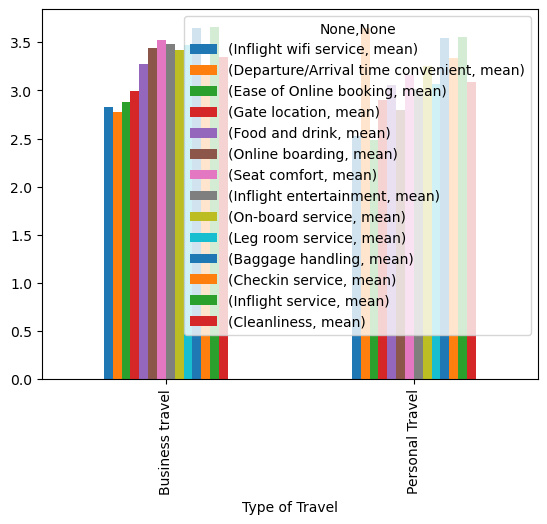

In [4]:
df.groupby('Type of Travel')[['Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 
    'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment',
   'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service',
   'Inflight service', 'Cleanliness']].agg(['mean']).plot(kind='bar')

Самые высокие показатели у командировочных:
- комфортность сидений
- удобство места для ног
- обслуживание в полете
- сервис в полете
- обработка багажа

Самые низкие показатели у командировочных:
- времени отправления и прибытия
- Wi-fi
- легкость онлайн бронирования

Самые высокие показатели у летящих в отпуск:
- времени отправления и прибытия
- обработка багажа
- обслуживание в полете

Самые низкие показатели у летящих в отпуск:
- Wi-fi
- легкость онлайн бронирования
- онлайн-регистрация

Вывод:

- Командировочные по всем параметрам более довольны, чем летящие в отпуск, кроме времени отправления и прибытия.
- одинаково низкие показатели по обеим группам: Wi-fi и легкостью онлайн бронирования 
- одинаково высокие показатели по обеим группам: обслуживание в полете и обработка багажа
- удобство и комфорт высокий уровень у коммандировочных
- а вот по времени отправления и прибытия мнения разделились, у командировочных это самый низкий показатель, а у летящих в отпуск самый высокий. Возможно это связано с тем, что для тех кто летит по делам время более ценно, чем у тех кто расслаблен и едет отдыхать.


Теперь проверим тоже самое, но в зависимости от класса

In [97]:
df.groupby('Class')[['Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 
    'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment',
   'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service',
   'Inflight service', 'Cleanliness']].agg(['mean']).unstack()

                                         Class   
Inflight wifi service              mean  Business    2.769924
                                         Eco         2.694871
                                         Eco Plus    2.708389
Departure/Arrival time convenient  mean  Business    2.876652
                                         Eco         3.196927
                                         Eco Plus    3.161119
Ease of Online booking             mean  Business    2.904085
                                         Eco         2.617182
                                         Eco Plus    2.607190
Gate location                      mean  Business    2.971566
                                         Eco         2.979009
                                         Eco Plus    2.886818
Food and drink                     mean  Business    3.349019
                                         Eco         3.070548
                                         Eco Plus    3.127830
Online boarding     

Самые высокие показатели у бизнес-класса:
- онлайн-регистрация
- комфортность сидений
- развлечения в полете
- удобство места для ног
- обработка багажа
- обслуживание в полете
- сервис в полете
- чистота

Самые низкие показатели у бизнес-класса:
- времени отправления и прибытия
- Wi-fi
- легкость онлайн бронирования

Самые высокие показатели у эконома:
- обработка багажа
- обслуживание в полете

Самые низкие показатели у эконома:
- Wi-fi
- легкость онлайн бронирования
- онлайн-регистрация

Вывод:

- В бизнес-классе по всем параметрам более довольны, чем летящие в отпуск, кроме времени отправления и прибытия.
- одинаково низкие показатели по обеим группам: Wi-fi и легкостью онлайн бронирования 
- одинаково высокие показатели по обеим группам: обслуживание в полете и обработка багажа
- удобство и комфорт высокий уровень у бизнес-класса

**Итоговый Вывод:**

- В основном число довольных среди клиентов летящих в деловые поездки бизнес-классом. Для них важно время отправления и прибытия, Wifi, а также обслуживание в полете и, конечно, комфорт.
- В основном число недовольных среди клиентов летящих в личных целях эконом-классом. Для них не так важно время отправления и прибытия, но важен Wifi, обслуживание в полете, онлайн бронирование и онлайн регистрация, комфорт.
  
В целом клиенты летящие в командировки более довольны, чем клиенты, летящие в личных целях. Возможно это связано, с тем что люди летящие в личных целях едут за свои личные средства и хотели бы получить больший комфорт и более придирчивые, чем те, которые летят за счет компании и не рискуют своими личными средствами.